# Financial Document Classification – Training & Evaluation

**Use case.** This project builds on my Introduction to Machine Learning summative (*credit card default
risk prediction*, tabular data). Before a lender can score a credit application, the documents the
applicant submits (invoices, budgets, forms, letters, resumes, ...) must be sorted. This notebook trains an
**image** classifier that recognises the document type from a scanned page.

**Dataset.** [RVL-CDIP small-200](https://huggingface.co/datasets/vaclavpechtor/rvl_cdip-small-200), a
200-images-per-class subset of RVL-CDIP (Harley, Ufkes & Derpanis, *ICDAR 2015*). We keep the 9 document
types a lender would receive with a credit application.

**Contents.** 1) Data acquisition · 2) Exploration · 3) Preprocessing · 4) Model creation · 5) Training ·
6) Evaluation (accuracy, precision, recall, F1, confusion matrix, report) · 7) Prediction functions ·
8) Saving & registering the model.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # run from notebook/ -> import the project's src package
os.chdir(Path.cwd().parent)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from src.config import CLASS_NAMES, TRAIN_DIR, VAL_DIR, TEST_DIR, SAMPLES_DIR, MODELS_DIR, EPOCHS, BATCH_SIZE, IMG_SIZE
from src import preprocessing, model as M, registry
from src.dataset_stats import compute_stats

sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| classes:", CLASS_NAMES)

TensorFlow 2.18.0 | classes: ['budget', 'email', 'form', 'handwritten', 'invoice', 'letter', 'memo', 'questionnaire', 'resume']


## 1. Data acquisition
`scripts/download_data.py` downloads only our 9 classes from Hugging Face, converts the TIFF scans to
grayscale PNG and builds the splits:

* source *train* (160/class) → our **train (80%)** and **validation (20%)**, stratified with a fixed seed
* source *validation* (40/class) → our **test** set, held out and never used for training or model selection

In [2]:
stats = compute_stats()
dist = stats["distribution"]
for split in ("train", "val", "test"):
    print(f"{split:5s}", sum(dist[split].values()), dist[split])

train 1152 {'budget': 128, 'email': 128, 'form': 128, 'handwritten': 128, 'invoice': 128, 'letter': 128, 'memo': 128, 'questionnaire': 128, 'resume': 128}
val   288 {'budget': 32, 'email': 32, 'form': 32, 'handwritten': 32, 'invoice': 32, 'letter': 32, 'memo': 32, 'questionnaire': 32, 'resume': 32}
test  360 {'budget': 40, 'email': 40, 'form': 40, 'handwritten': 40, 'invoice': 40, 'letter': 40, 'memo': 40, 'questionnaire': 40, 'resume': 40}


## 2. Data exploration
### 2.1 Example documents per class

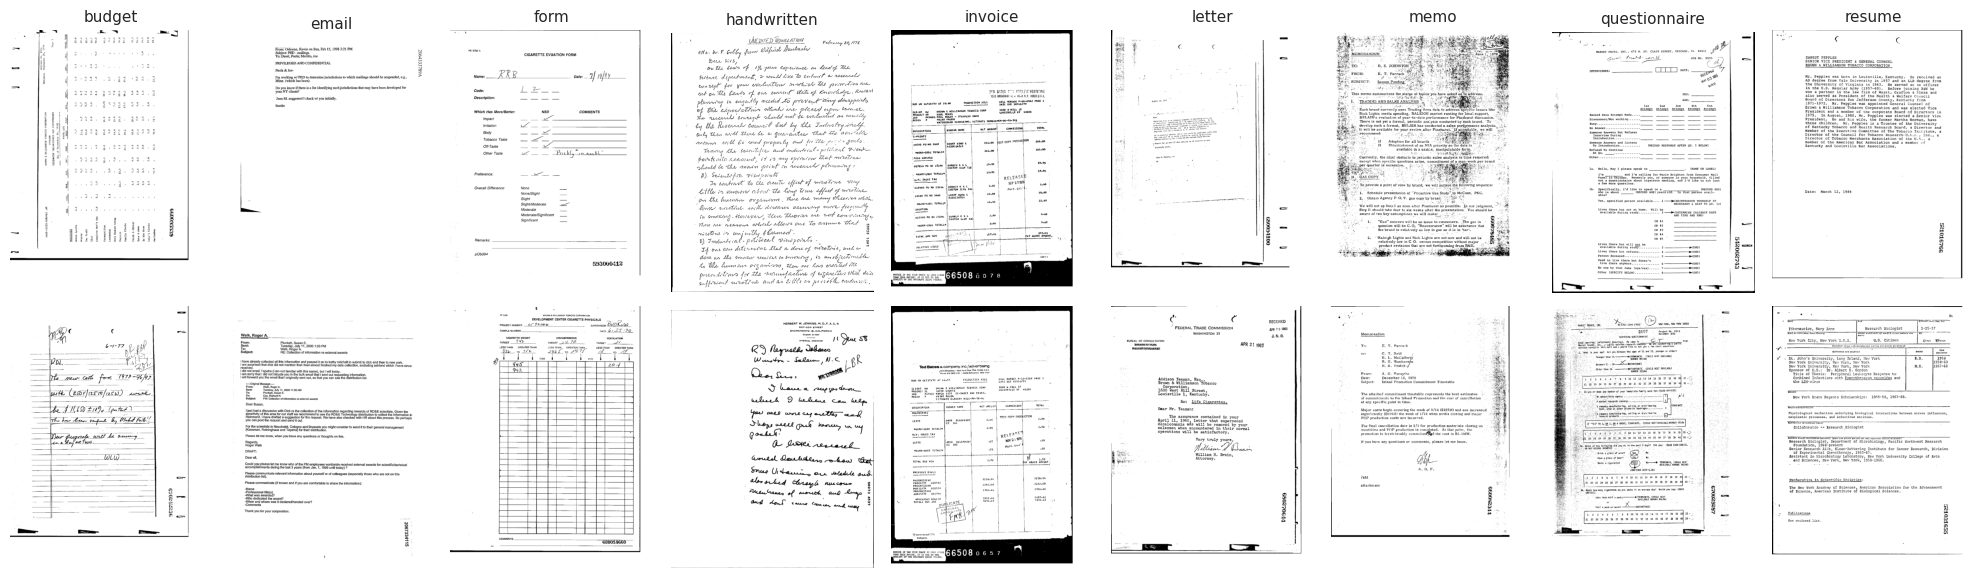

In [3]:
fig, axes = plt.subplots(2, 9, figsize=(20, 6))
for col, c in enumerate(CLASS_NAMES):
    files = sorted((TRAIN_DIR / c).glob("*.png"))[:2]
    for row, f in enumerate(files):
        axes[row, col].imshow(plt.imread(f), cmap="gray")
        axes[row, col].set_title(c if row == 0 else "", fontsize=11)
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

### 2.2 Feature 1 – class distribution

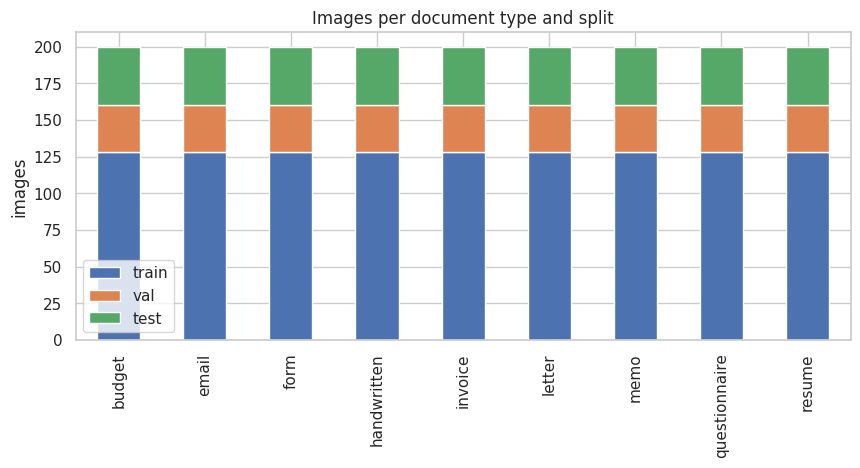

,train,val,test
budget,128,32,40
email,128,32,40
form,128,32,40
handwritten,128,32,40
invoice,128,32,40
letter,128,32,40
memo,128,32,40
questionnaire,128,32,40
resume,128,32,40


In [4]:
import pandas as pd
df_dist = pd.DataFrame(dist)
df_dist.plot(kind="bar", stacked=True, figsize=(10, 4), title="Images per document type and split")
plt.ylabel("images"); plt.show()
df_dist

**Interpretation.** The dataset is perfectly balanced (128 train / 32 val / 40 test per type), so accuracy is
a fair headline metric and no class weighting or resampling is needed. In real lending data, invoices and
forms would dominate; this is a limitation discussed in the report.

### 2.3 Feature 2 – page geometry (width, height, aspect ratio)

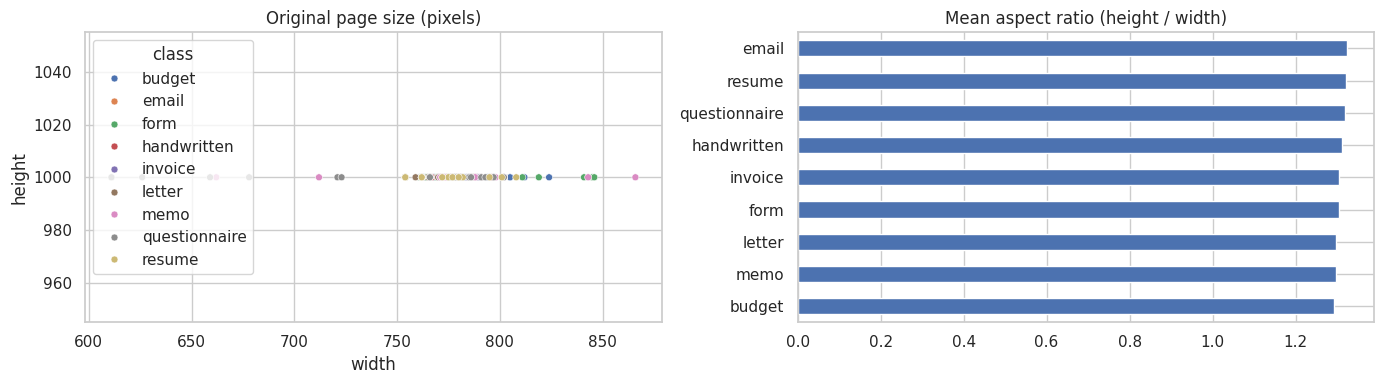

,width,height,aspect_ratio
budget,773.54,1000.0,1.29
email,755.96,1000.0,1.32
form,767.61,1000.0,1.30
handwritten,761.97,1000.0,1.31
invoice,766.42,1000.0,1.31
letter,770.80,1000.0,1.30
memo,771.26,1000.0,1.30
questionnaire,760.56,1000.0,1.32
resume,757.32,1000.0,1.32


In [5]:
sizes = pd.DataFrame(stats["sizes"])
feat = pd.DataFrame({c: {k: v["mean"] for k, v in f.items()} for c, f in stats["per_class_features"].items()}).T
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=sizes, x="width", y="height", hue="class", ax=ax[0], s=25)
ax[0].set_title("Original page size (pixels)")
feat["aspect_ratio"].sort_values().plot(kind="barh", ax=ax[1], title="Mean aspect ratio (height / width)")
plt.tight_layout(); plt.show()
feat[["width", "height", "aspect_ratio"]].round(2)

**Interpretation.** Almost every scan has the same height (~1000 px) with widths around 750–800 px – a portrait
page with aspect ratio ≈ 1.3. Page **shape carries almost no information about the class**, so the model has
to learn from the *layout* inside the page. Resizing to a square 224×224 slightly squashes pages, but it is
the same distortion for every class, so it does not bias the model.

### 2.4 Feature 3 – ink density and brightness

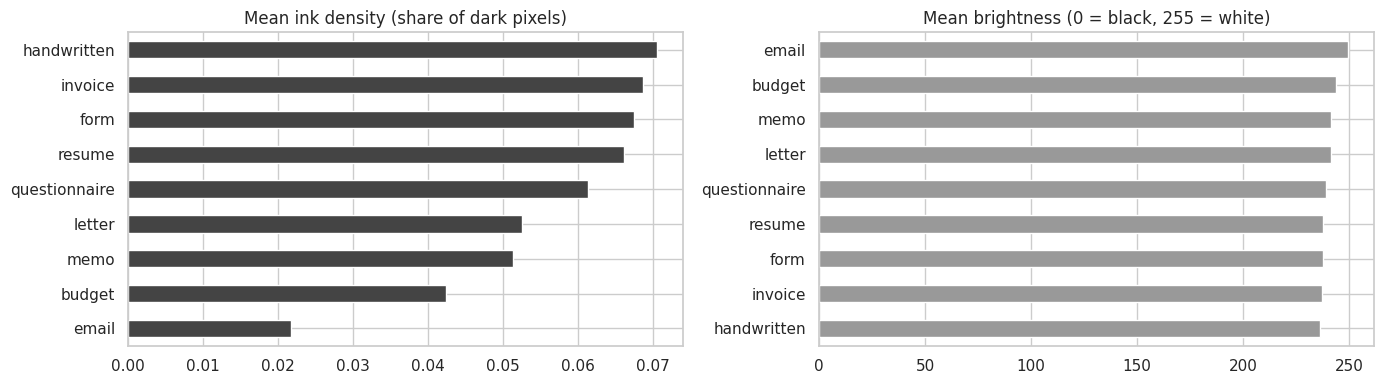

,ink_density,brightness
budget,0.042,243.882
email,0.022,249.329
form,0.068,237.537
handwritten,0.071,236.499
invoice,0.069,237.153
letter,0.053,241.319
memo,0.051,241.573
questionnaire,0.061,238.932
resume,0.066,237.800


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
feat["ink_density"].sort_values().plot(kind="barh", ax=ax[0], color="#444", title="Mean ink density (share of dark pixels)")
feat["brightness"].sort_values().plot(kind="barh", ax=ax[1], color="#999", title="Mean brightness (0 = black, 255 = white)")
plt.tight_layout(); plt.show()
feat[["ink_density", "brightness"]].round(3)

**Interpretation.** Document types differ clearly in how much ink they carry: dense, structured types
(forms, budgets, handwritten notes, questionnaires) have more dark pixels than sparse text types (letters,
memos). This visual difference is exactly what a CNN can learn. Types with similar ink density
(e.g. letter vs. memo vs. email) are where we expect the most confusion.

## 3. Preprocessing
Implemented in `src/preprocessing.py` and inside the model (`src/model.py`):

| Step | Where | Why |
|---|---|---|
| Decode PNG/JPEG/TIFF with Pillow | `load_image` | one loader for every format users may upload |
| Convert to grayscale, then repeat to 3 channels | `load_image` | scans are black & white; MobileNetV2 expects RGB |
| Resize to 224×224 | `load_image` | MobileNetV2's native input size |
| Label encoding (name → index) | `encode_label` | fixed class order shared by training and the API |
| Augmentation: rotation ±2%, shift ±5%, zoom ±10% (training only) | model layer | imitates crooked scans → less overfitting with only 128 images/class |
| Normalise to [-1, 1] | model layer | MobileNetV2's expected range; inside the model so prediction can never use a different scaling |

In [7]:
t0 = time.time()
x_train, y_train = preprocessing.load_dataset(TRAIN_DIR)
x_val, y_val = preprocessing.load_dataset(VAL_DIR)
x_test, y_test = preprocessing.load_dataset(TEST_DIR)
print(f"train {x_train.shape}, val {x_val.shape}, test {x_test.shape}  dtype={x_train.dtype}  ({time.time()-t0:.0f}s)")

train (1152, 224, 224, 3), val (288, 224, 224, 3), test (360, 224, 224, 3)  dtype=uint8  (20s)


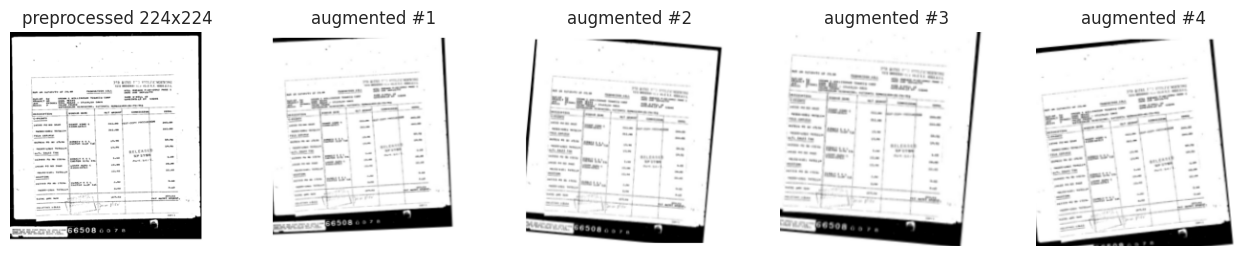

In [8]:
# Visualise preprocessing and augmentation on one invoice
sample = x_train[y_train == CLASS_NAMES.index("invoice")][0]
aug = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.02, fill_mode="constant", fill_value=255.0),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=255.0),
    tf.keras.layers.RandomZoom(0.1, fill_mode="constant", fill_value=255.0)])
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(sample); axes[0].set_title("preprocessed 224x224")
for i in range(1, 5):
    axes[i].imshow(aug(sample[None].astype("float32"), training=True)[0].numpy().astype("uint8"))
    axes[i].set_title(f"augmented #{i}")
for a in axes: a.axis("off")
plt.show()

## 4. Model creation – MobileNetV2 transfer learning
**Why MobileNetV2?** With only 128 training images per class, training a CNN from scratch would overfit.
MobileNetV2 was pretrained on 1.2M ImageNet photos and already detects edges, lines, blocks and textures.
We reuse those features and train a new 9-class head. It is small (~3.5M parameters, ~10 MB) and fast on
CPU, which matters for serving many requests in the load test.

In [9]:
model = M.build_model()
model.summary(show_trainable=True)

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  16384/9406464 ━━━━━━━━━━━━━━━━━━━━ 1:14 8us/step

  32768/9406464 ━━━━━━━━━━━━━━━━━━━━ 53s 6us/step 

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 46s 5us/step

  65536/9406464 ━━━━━━━━━━━━━━━━━━━━ 42s 5us/step

  90112/9406464 ━━━━━━━━━━━━━━━━━━━━ 37s 4us/step

... (23 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ normalize (Rescaling)       │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 9)             │     11,529 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Training
**Stage 1 – feature extraction:** backbone frozen, only the classifier head is trained (Adam, lr 1e-3).
**Stage 2 – fine-tuning:** the top 30 backbone layers are unfrozen with lr 1e-5 so they adapt from photos to
document layouts. Early stopping on validation accuracy (patience 4) restores the best weights.

In [10]:
t0 = time.time()
history = M.train(model, x_train, y_train, x_val, y_val, epochs=EPOCHS, fine_tune_epochs=8, batch_size=BATCH_SIZE)
train_seconds = time.time() - t0
print(f"training time: {train_seconds/60:.1f} min")

Epoch 1/15


36/36 - 36s - 1s/step - accuracy: 0.2457 - loss: 2.1344 - val_accuracy: 0.3611 - val_loss: 1.8424


Epoch 2/15


36/36 - 29s - 797ms/step - accuracy: 0.3993 - loss: 1.7051 - val_accuracy: 0.4201 - val_loss: 1.7257


Epoch 3/15


36/36 - 28s - 782ms/step - accuracy: 0.4948 - loss: 1.4837 - val_accuracy: 0.4167 - val_loss: 1.6838


... (33 outputs left out)

36/36 - 35s - 965ms/step - accuracy: 0.6641 - loss: 0.9352 - val_accuracy: 0.5035 - val_loss: 1.5105


Epoch 8/8


36/36 - 37s - 1s/step - accuracy: 0.6927 - loss: 0.8791 - val_accuracy: 0.4931 - val_loss: 1.5699


training time: 11.4 min


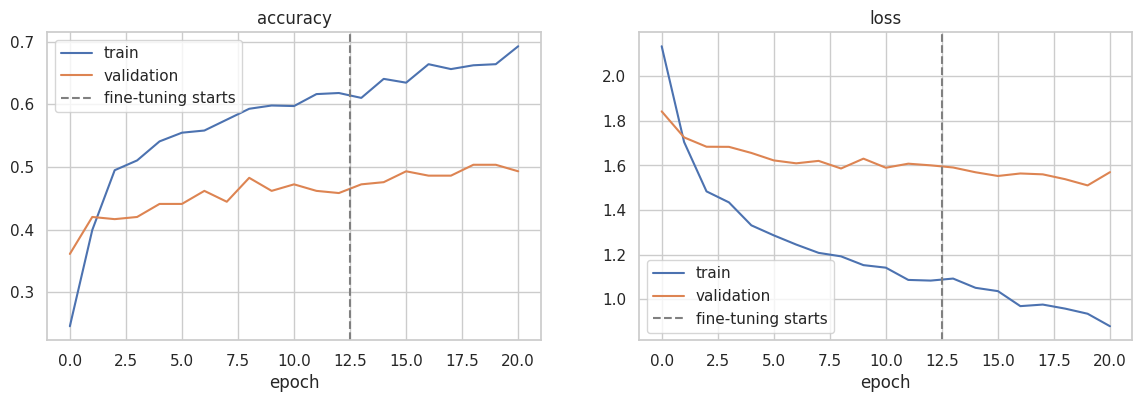

In [11]:
ft = history["fine_tune_start_epoch"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for metric, a in zip(("accuracy", "loss"), ax):
    a.plot(history[metric], label="train"); a.plot(history["val_" + metric], label="validation")
    a.axvline(ft - 0.5, ls="--", c="gray", label="fine-tuning starts")
    a.set_title(metric); a.set_xlabel("epoch"); a.legend()
plt.show()

**Reading the curves.** Validation accuracy rises quickly in stage 1 (the pretrained features are already
useful) and improves again after fine-tuning starts. A gap where training accuracy is far above validation
accuracy would indicate overfitting; augmentation, dropout and early stopping are there to limit it.

## 6. Evaluation on the held-out test set

In [12]:
metrics = M.evaluate(model, x_test, y_test)
print(f"Accuracy          {metrics['accuracy']:.3f}")
print(f"Precision (macro) {metrics['precision_macro']:.3f}")
print(f"Recall (macro)    {metrics['recall_macro']:.3f}")
print(f"F1-score (macro)  {metrics['f1_macro']:.3f}")

Accuracy          0.522
Precision (macro) 0.526
Recall (macro)    0.522
F1-score (macro)  0.491


In [13]:
pd.DataFrame(metrics["classification_report"]).T.round(3)

,precision,recall,f1-score,support
budget,0.362,0.625,0.459,40.000
email,0.821,0.800,0.810,40.000
form,0.318,0.175,0.226,40.000
handwritten,0.630,0.850,0.723,40.000
invoice,0.419,0.450,0.434,40.000
letter,0.714,0.500,0.588,40.000
memo,0.333,0.275,0.301,40.000
questionnaire,0.571,0.100,0.170,40.000
resume,0.569,0.925,0.705,40.000
accuracy,0.522,0.522,0.522,0.522


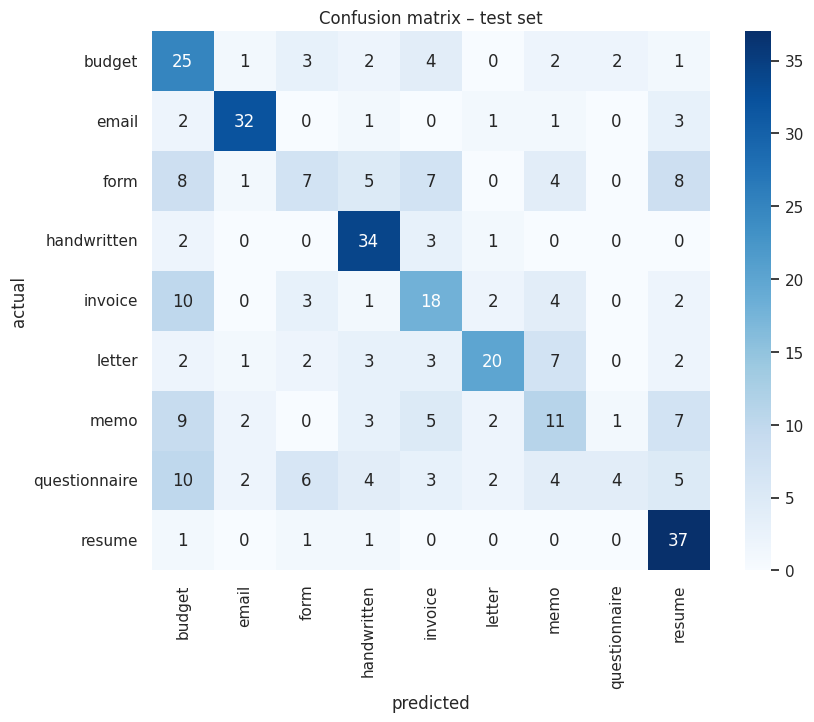

In [14]:
cm = np.array(metrics["confusion_matrix"])
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("Confusion matrix – test set")
plt.show()

In [15]:
# Most frequent confusions (off-diagonal cells)
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j]]
pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:8], columns=["actual", "predicted", "count"])

,actual,predicted,count
0,invoice,budget,10
1,questionnaire,budget,10
2,memo,budget,9
3,form,budget,8
4,form,resume,8
5,form,invoice,7
6,letter,memo,7
7,memo,resume,7


### Interpretation of the results
See the cell below – it is generated from the actual numbers.

In [16]:
rep = metrics["classification_report"]
f1s = {c: rep[c]["f1-score"] for c in CLASS_NAMES}
best, worst = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
print(f"Overall: {metrics['accuracy']:.1%} accuracy on {metrics['n_samples']} unseen documents "
      f"(random guessing = {1/len(CLASS_NAMES):.1%}).")
print(f"Easiest type: {best} (F1 {f1s[best]:.2f}); hardest type: {worst} (F1 {f1s[worst]:.2f}).")
print("Macro precision ≈ recall means errors are spread evenly rather than one class absorbing predictions.")

Overall: 52.2% accuracy on 360 unseen documents (random guessing = 11.1%).
Easiest type: email (F1 0.81); hardest type: questionnaire (F1 0.17).
Macro precision ≈ recall means errors are spread evenly rather than one class absorbing predictions.


**What this means for a lender.** Because the classes are balanced, macro-averaged precision, recall and
F1 weigh every document type equally. Precision answers *"when the model says invoice, how often is it
really an invoice?"*; recall answers *"of all invoices, how many did it find?"*. Confusions concentrate between
visually similar text-only types (letter / memo / email), while structured types with distinctive layouts are
recognised more reliably. In production, low-confidence predictions should be routed to a human reviewer
rather than processed automatically.

## 7. Prediction functions

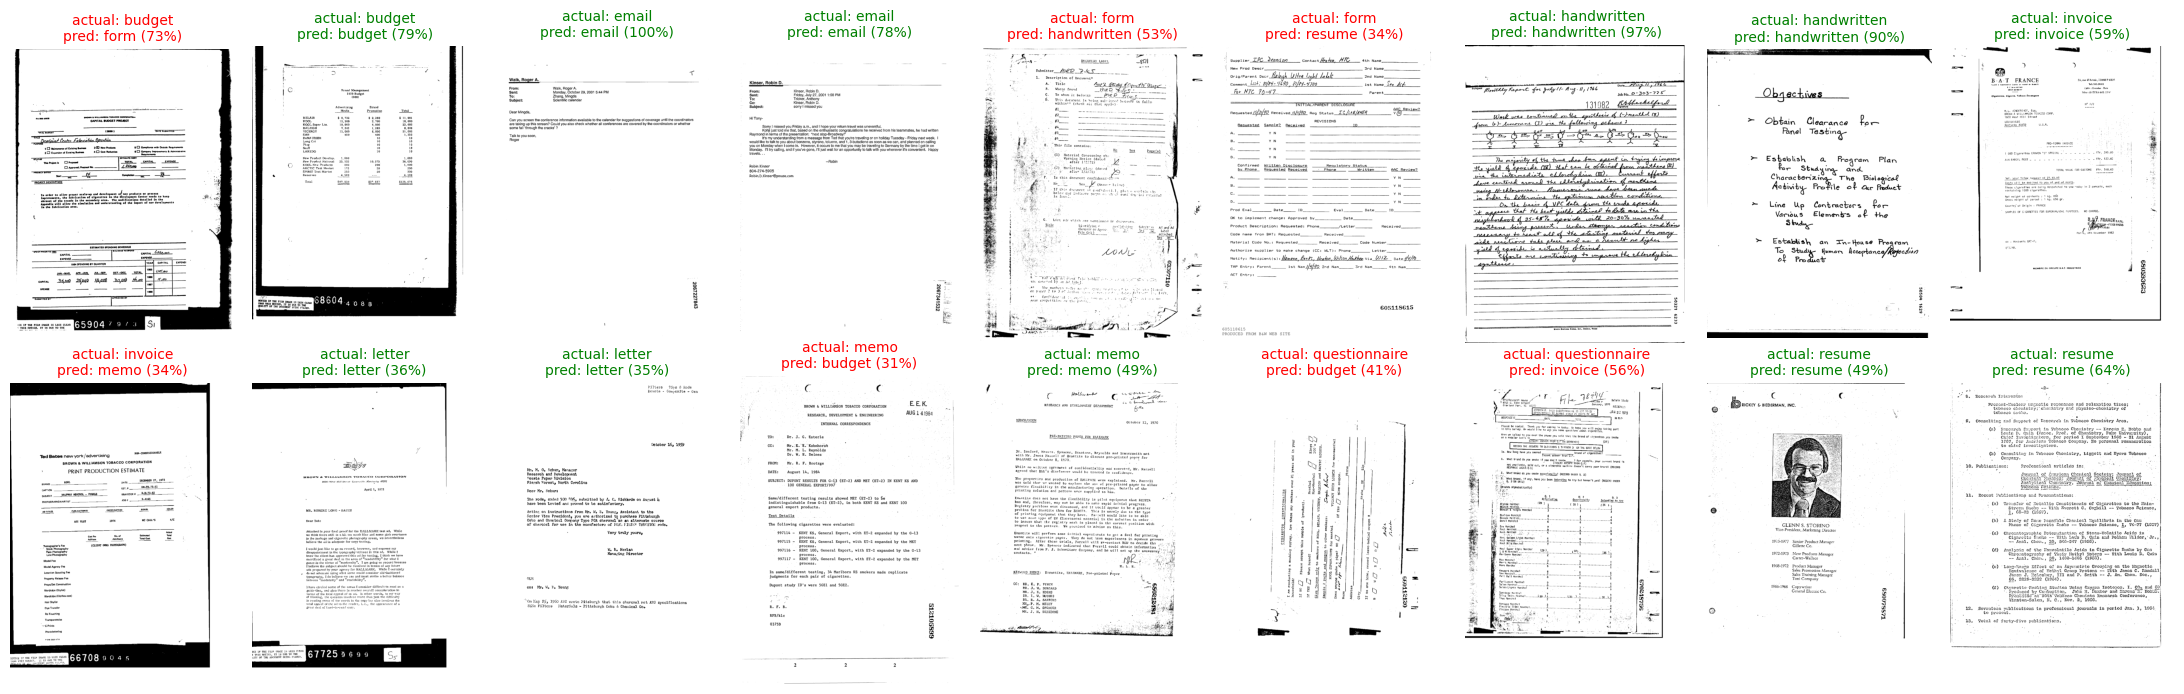

In [17]:
from src.prediction import Predictor

def predict_document(path, model=model):
    """Preprocess one image file and return (class, confidence, all probabilities)."""
    x = preprocessing.load_image(path)[None]
    probs = model(x, training=False).numpy()[0]
    return CLASS_NAMES[int(probs.argmax())], float(probs.max()), dict(zip(CLASS_NAMES, probs.round(3)))

samples = sorted(SAMPLES_DIR.glob("*.png"))
fig, axes = plt.subplots(2, 9, figsize=(22, 7))
for ax, f in zip(axes.flat, samples):
    label, conf, _ = predict_document(f)
    actual = f.name.split("_")[0]
    ax.imshow(plt.imread(f), cmap="gray"); ax.axis("off")
    ax.set_title(f"actual: {actual}\npred: {label} ({conf:.0%})", color="green" if label == actual else "red", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Save and register the model (version 1)

In [18]:
version = registry.next_version()
filename = f"doc_classifier_v{version}.h5"
M.save_model(model, MODELS_DIR / filename)
M.save_json(metrics, MODELS_DIR / "metrics.json")
M.save_json(history, MODELS_DIR / "history.json")
registry.record({
    "version": version, "file": filename, "kind": "initial", "status": "promoted",
    "created_at": registry.now_iso(), "train_samples": int(len(x_train)),
    "training_seconds": round(train_seconds, 1),
    "metrics": {k: metrics[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro")},
}, promote=True)
print("saved", MODELS_DIR / filename, f"{(MODELS_DIR / filename).stat().st_size/1e6:.1f} MB")

saved /app/models/doc_classifier_v1.h5 21.6 MB


In [19]:
# Sanity check: the saved .h5 file reloads and the API's Predictor gives the same answer
p = Predictor()
f = samples[0]
print("notebook model:", predict_document(f)[:2])
print("reloaded model:", (lambda r: (r["predicted_class"], round(r["confidence"], 4)))(p.predict(f)), "version", p.version)

notebook model: ('form', 0.7300372123718262)


reloaded model: ('form', 0.73) version 1
